# DS2002 · Critique and Redesign

**Studio — 2026-11-11 · Fall 2026**  
**Class time:** 45 minutes

---

## Critique, then rebuild twice

Charts do not get good in one pass. Today you take three bad charts through two iterations each: fix the mechanics first, then sharpen the argument.

That split is deliberate. Iteration one is checkable — labels, sorting, units, layout. Iteration two is the judgment part: what is this chart actually claiming, and is the claim the most useful one available in the data?

Bring your midterm charts to the last section. We will run the rubric on real work.

### The rubric

Score any chart out of 6. This is the same rubric used on both project presentations, so learn to run it on your own work.

| # | Criterion | Fails when |
|---|---|---|
| 1 | Title states a finding | Title names the columns |
| 2 | Axes labeled with units | "Revenue" with no currency; no axis label |
| 3 | Right chart for the question | Pie for comparison; bars for a trend |
| 4 | Honest scale | Truncated bar axis; unnormalized comparison |
| 5 | Readable | Overlapping labels, clipped text, unsorted categories |
| 6 | No wasted ink | Decoration, redundant legends, chart junk |

Run this cell so we all score the same way.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

CRITERIA = ['title states a finding', 'axes labeled with units',
            'right chart for the question', 'honest scale',
            'readable', 'no wasted ink']

def score(**passed):
    """score(title=False, axes=True, ...) -> prints a scored critique."""
    total = 0
    for name, ok in zip(CRITERIA, passed.values()):
        print(('PASS' if ok else 'FAIL'), '-', name)
        total += bool(ok)
    print(f'\nscore: {total}/6')
    return total

### Chart 1 — the pie chart

Here is the chart that shows up in roughly a third of student decks.

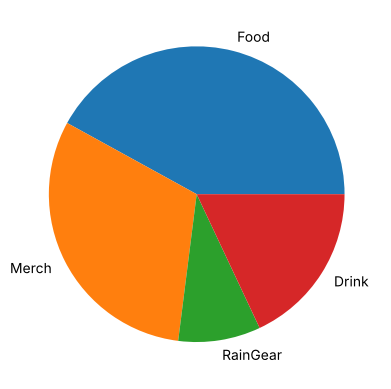

In [2]:
cats = ['Food', 'Merch', 'RainGear', 'Drink']
vals = [4200, 3100, 900, 1800]
plt.pie(vals, labels=cats)
plt.show()

**TODO:** score it. Then say in a comment which two slices you cannot rank by eye — that is the concrete cost of the chart type, not a matter of taste.

In [3]:
score(title=False,       # no title at all, let alone a finding
      axes=False,        # no unit anywhere: dollars? units sold?
      chart_type=False,  # pie for a ranking/comparison question
      scale=True,        # shares of a whole, nothing truncated
      readable=False,    # slices in data order, no values, Drink and RainGear squeezed together
      ink=True)          # no decoration to strip

# Ambiguous: Food vs Merch. They are the two big wedges (42% vs 31% of $10,000), they start at
# different angles, and the eye cannot compare angles/areas reliably: without the numbers you
# cannot say by how much Food leads, and side by side at a glance they read as roughly "both big".
# That is the cost of the chart type: a pie asks the reader to compare angles, a bar compares
# lengths on a common baseline, which people do accurately.

FAIL - title states a finding
FAIL - axes labeled with units
FAIL - right chart for the question
PASS - honest scale
FAIL - readable
PASS - no wasted ink

score: 2/6


2

**Iteration 1 — fix the mechanics.**

**TODO:** rebuild as a sorted horizontal bar chart. Title, axis label with unit, top and right spines removed, value labels on the bars, `tight_layout()`. Do not worry yet about whether the message is the best one available.

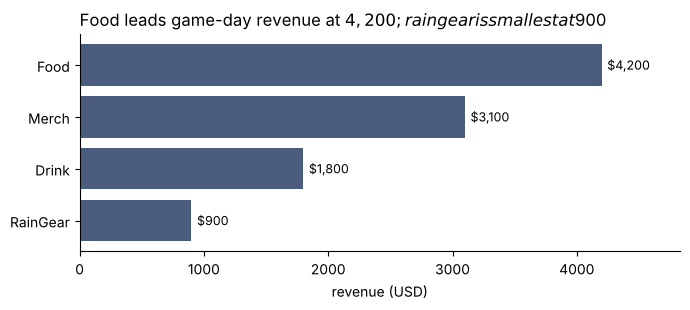

PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6


6

In [4]:
rev = pd.Series(vals, index=cats).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh(rev.index, rev.values, color='#4a5d7e')
ax.bar_label(bars, labels=[f'${v:,.0f}' for v in rev.values], padding=4, fontsize=9)
ax.set_title(f'Food leads game-day revenue at ${rev.max():,.0f}; rain gear is smallest at ${rev.min():,.0f}',
             loc='left', fontsize=12)
ax.set_xlabel('revenue (USD)')
ax.set_xlim(0, rev.max() * 1.15)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

score(title=True, axes=True, chart_type=True, scale=True, readable=True, ink=True)

**Iteration 2 — sharpen the argument.**

The mechanical version probably says something like "Food leads revenue." True, and not very useful — food leads revenue at every game.

**TODO:** the more interesting fact is in this second frame: rain gear is tiny in total but enormous relative to how often it sells. Build a chart that makes *that* the claim, and write the title as the claim.

In [5]:
detail = pd.DataFrame({
    'category': ['Food', 'Merch', 'RainGear', 'Drink'],
    'revenue': [4200, 3100, 900, 1800],
    'games_sold_in': [6, 6, 2, 6],   # rain gear only moves on wet days
}).set_index('category')
detail['revenue_per_game'] = detail['revenue'] / detail['games_sold_in']
detail

,revenue,games_sold_in,revenue_per_game
category,,,
Food,4200,6,700.000000
Merch,3100,6,516.666667
RainGear,900,2,450.000000
Drink,1800,6,300.000000


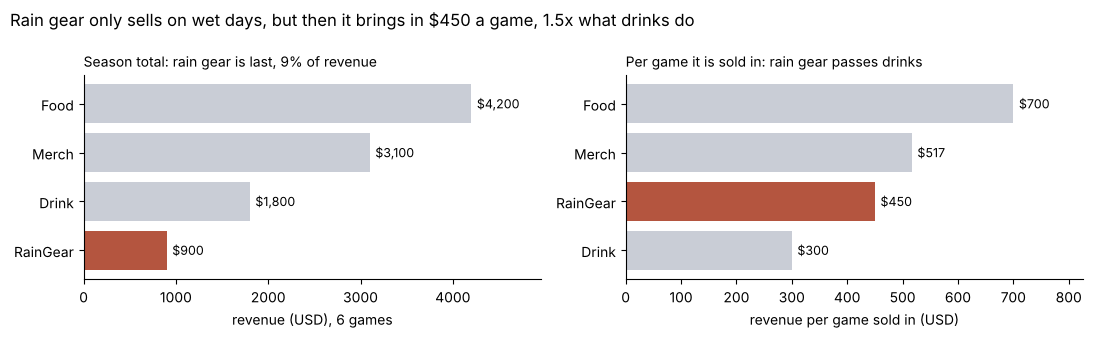

In [6]:
total = detail['revenue'].sort_values()
per_game = detail['revenue_per_game'].sort_values()
highlight = lambda idx: ['#b4553f' if c == 'RainGear' else '#c9cdd6' for c in idx]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
b0 = axes[0].barh(total.index, total.values, color=highlight(total.index))
axes[0].bar_label(b0, labels=[f'${v:,.0f}' for v in total.values], padding=4, fontsize=9)
axes[0].set_title('Season total: rain gear is last, 9% of revenue', loc='left', fontsize=10)
axes[0].set_xlabel('revenue (USD), 6 games')
axes[0].set_xlim(0, total.max() * 1.18)

b1 = axes[1].barh(per_game.index, per_game.values, color=highlight(per_game.index))
axes[1].bar_label(b1, labels=[f'${v:,.0f}' for v in per_game.values], padding=4, fontsize=9)
axes[1].set_title('Per game it is sold in: rain gear passes drinks', loc='left', fontsize=10)
axes[1].set_xlabel('revenue per game sold in (USD)')
axes[1].set_xlim(0, per_game.max() * 1.18)
for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)

rg, dr = detail.loc['RainGear', 'revenue_per_game'], detail.loc['Drink', 'revenue_per_game']
fig.suptitle(f'Rain gear only sells on wet days, but then it brings in ${rg:,.0f} a game, '
             f'{rg / dr:.1f}x what drinks do', x=0.01, ha='left', fontsize=12)
plt.tight_layout()
plt.show()

### Chart 2 — the misleading axis

**TODO:** score this one, name the specific problem, and rebuild it honestly. Then answer: is the difference between these zones worth acting on?

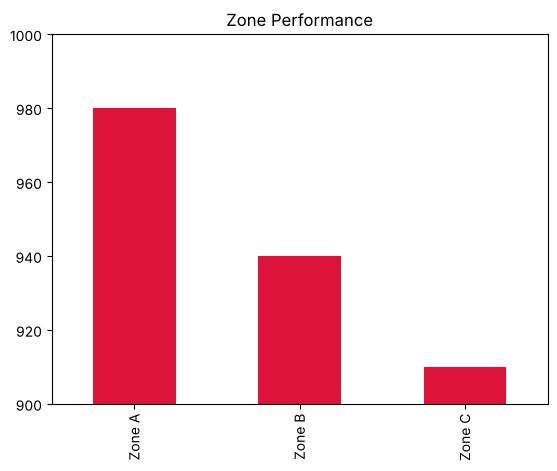

In [7]:
zones = pd.Series({'Zone A': 980, 'Zone B': 940, 'Zone C': 910})
zones.plot(kind='bar', color='crimson')
plt.ylim(900, 1000)
plt.title('Zone Performance')
plt.show()

FAIL - title states a finding
FAIL - axes labeled with units
PASS - right chart for the question
FAIL - honest scale
PASS - readable
FAIL - no wasted ink

score: 2/6


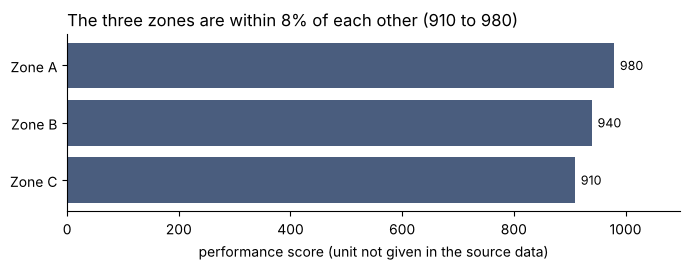

PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6


6

In [8]:
score(title=False,       # "Zone Performance" names a topic, not a finding
      axes=False,        # no y label, no unit (orders? dollars?)
      chart_type=True,   # bars are right for comparing three zones
      scale=False,       # y-axis starts at 900, on a bar chart
      readable=True,     # three short labels, already in descending order
      ink=False)         # crimson implies alarm/meaning it does not carry; no value labels to make up for it

# The specific problem: ylim(900, 1000) truncates the bars. Zone A's bar is drawn 8x as tall as
# Zone C's (80 vs 10 above the cutoff) when A is only 7.7% higher (980 vs 910).
z = zones.sort_values()
fig, ax = plt.subplots(figsize=(7, 2.8))
bars = ax.barh(z.index, z.values, color='#4a5d7e')
ax.bar_label(bars, labels=[f'{v:,.0f}' for v in z.values], padding=4, fontsize=9)
spread = z.max() / z.min() - 1
ax.set_title(f'The three zones are within {spread:.0%} of each other ({z.min():,.0f} to {z.max():,.0f})',
             loc='left', fontsize=12)
ax.set_xlabel('performance score (unit not given in the source data)')
ax.set_xlim(0, z.max() * 1.12)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

score(title=True, axes=True, chart_type=True, scale=True, readable=True, ink=True)

# Is the gap worth acting on? Not on this evidence. It is a 70-point (7.7%) spread from one
# number per zone, with no unit, no variation across games and no sense of what moves the
# number. Before moving staff or stock, check whether Zone A beats Zone C game after game; if
# the gap holds at about 8% it is real but modest, and normalizing by foot traffic might erase it.

### Chart 3 — the unreadable time series

**TODO:** this one has a real message buried in it. Score it, then rebuild: pick the right chart type, annotate the moment that explains the shape, and title it with the staffing conclusion a manager should draw.

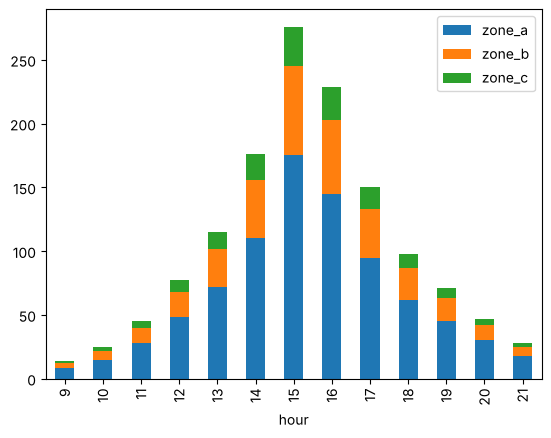

In [9]:
hourly = pd.DataFrame({
    'hour': list(range(9, 22)),
    'zone_a': [8, 15, 28, 48, 72, 110, 175, 145, 95, 62, 45, 30, 18],
    'zone_b': [4, 7, 12, 20, 30, 46, 70, 58, 38, 25, 18, 12, 7],
    'zone_c': [2, 3, 5, 9, 13, 20, 31, 26, 17, 11, 8, 5, 3],
}).set_index('hour')

hourly.plot(kind='bar', stacked=True)
plt.show()

FAIL - title states a finding
FAIL - axes labeled with units
FAIL - right chart for the question
PASS - honest scale
FAIL - readable
PASS - no wasted ink

score: 2/6


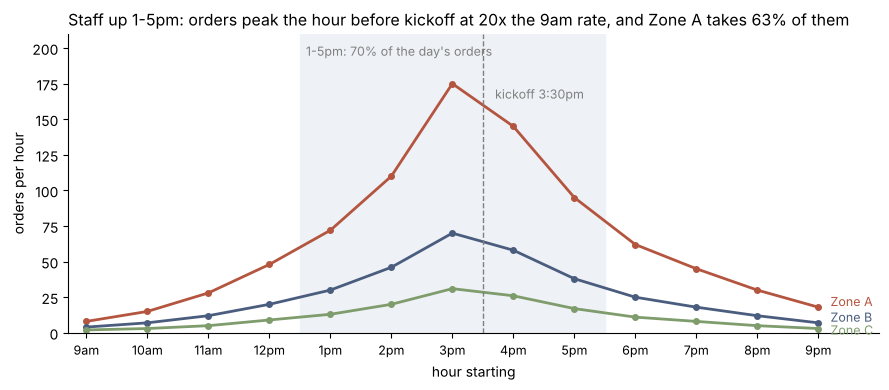

peak hour 15:00 (276 orders) vs 9am (14); Zone A share 63%
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6


6

In [10]:
score(title=False,       # no title
      axes=False,        # x is "hour" with no am/pm; y has no label or unit
      chart_type=False,  # stacked bars for a trend: only Zone A sits on a common baseline,
                         # B and C float on top of it, so their shapes cannot be compared
      scale=True,        # starts at zero, nothing truncated
      readable=False,    # sideways 24h numbers with no am/pm, raw column names in the legend
      ink=True)

share_a = hourly['zone_a'].sum() / hourly.sum().sum()
peak_hour = hourly.sum(axis=1).idxmax()
peak_total, quiet_total = hourly.sum(axis=1).max(), hourly.sum(axis=1).loc[9]
rush = hourly.loc[13:17]                                     # 1pm-5pm
rush_share = rush.sum().sum() / hourly.sum().sum()

fig, ax = plt.subplots(figsize=(9, 4))
ax.axvspan(12.5, 17.5, color='#eef1f5', zorder=0)
ax.text(12.6, hourly['zone_a'].max() * 1.1, f'1-5pm: {rush_share:.0%} of the day\'s orders',
        fontsize=9, color='gray', va='bottom')
styles = {'zone_a': ('Zone A', '#b4553f'), 'zone_b': ('Zone B', '#4a5d7e'), 'zone_c': ('Zone C', '#7f9c6c')}
nudge = {'zone_a': 4, 'zone_b': 4, 'zone_c': -1}   # keep end labels from overlapping
for col, (label, color) in styles.items():
    ax.plot(hourly.index, hourly[col], marker='o', ms=4, lw=2, color=color)
    ax.text(21.2, hourly[col].iloc[-1] + nudge[col], label, color=color, fontsize=9, va='center')  # direct labels, no legend
ax.axvline(15.5, ls='--', color='gray', lw=1)
ax.annotate('kickoff 3:30pm', xy=(15.5, hourly['zone_a'].max()), xytext=(15.7, hourly['zone_a'].max() * 0.94),
            fontsize=9, color='gray')
ax.set_xticks(hourly.index)
ax.set_xticklabels([f'{h % 12 or 12}{"am" if h < 12 else "pm"}' for h in hourly.index], fontsize=9)
ax.set_xlim(8.7, 22)
ax.set_ylim(0, hourly['zone_a'].max() * 1.2)
ax.set_xlabel('hour starting')
ax.set_ylabel('orders per hour')
ax.set_title(f'Staff up 1-5pm: orders peak the hour before kickoff at {peak_total / quiet_total:.0f}x the 9am rate, '
             f'and Zone A takes {share_a:.0%} of them', loc='left', fontsize=11.5)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print(f'peak hour {peak_hour}:00 ({peak_total} orders) vs 9am ({quiet_total}); Zone A share {share_a:.0%}')
score(title=True, axes=True, chart_type=True, scale=True, readable=True, ink=True)

### Your own work

**TODO:** open your midterm notebook, pick the chart you were least happy with, and paste it below. Score it with the rubric, then do one iteration.

If your midterm chart already scores 6, take the one you were *most* happy with and try to make the claim sharper instead.

               baseline    surge  multiple
category                                  
Breakfast         73.27   376.86      5.14
Emergency        354.07  1006.43      2.84
Electronics       70.27   175.86      2.50
Alcohol           61.53   138.86      2.26
Entertainment    101.60   228.57      2.25
Health            42.33    95.00      2.24
Household         85.13   176.29      2.07
Grocery          171.07   306.57      1.79
Baby              85.20   133.71      1.57
Snacks            58.53    73.71      1.26


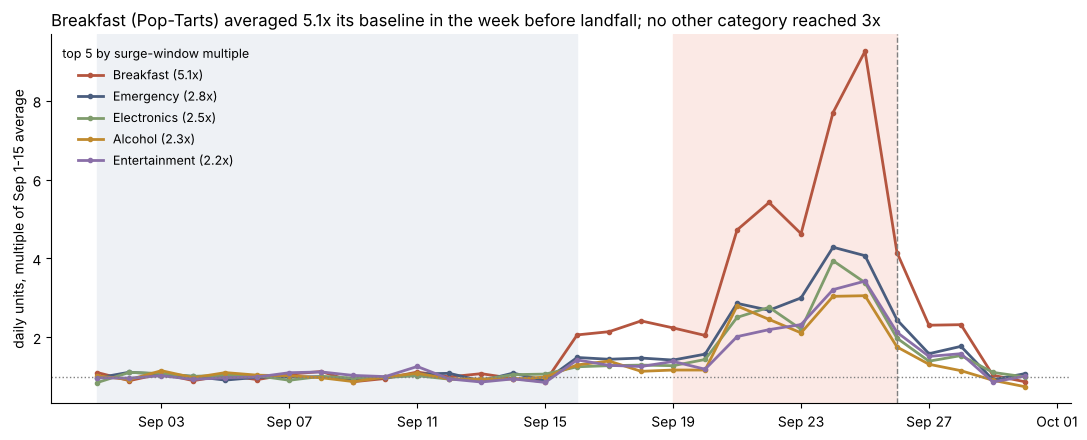

PASS - title states a finding
PASS - axes labeled with units
FAIL - right chart for the question
PASS - honest scale
FAIL - readable
PASS - no wasted ink

score: 4/6


4

In [11]:
# Midterm Q1 chart (2026-10-30 progress lab): category surge multiples around Hurricane Helene.
# Load and clean the team data exactly as the midterm did (only the steps Q1 needs).
import matplotlib.dates as mdates

TEAM_DATA = 'https://raw.githubusercontent.com/ayanrasulova/ds2002-midterm/fd1583a/data'
raw = pd.read_csv(f'{TEAM_DATA}/walmart_transactions.csv', dtype='string', keep_default_na=False)

MISSING_TOKENS = {'', 'NULL', 'N/A', 'NA', 'NAN', 'NONE'}
tx = raw.copy()
for col in tx.columns:
    v = tx[col].astype('string').str.strip()
    tx[col] = v.mask(v.str.upper().isin(MISSING_TOKENS), pd.NA)

def normalize_category(values):
    text = values.astype('string').str.strip().str.replace(r'\s+', ' ', regex=True)
    key = text.str.casefold().str.replace(r'[^a-z0-9]', '', regex=True)
    aliases = {
        'breakfastfoods': 'Breakfast', 'breakfast': 'Breakfast',
        'emergencysupplies': 'Emergency', 'emergency': 'Emergency',
        'alcoholicbeverages': 'Alcohol', 'alcohol': 'Alcohol',
        'entertainment': 'Entertainment', 'gamesentertainment': 'Entertainment',
        'electronics': 'Electronics', 'groceries': 'Grocery', 'grocery': 'Grocery',
        'householdessentials': 'Household', 'household': 'Household',
        'babyproducts': 'Baby', 'baby': 'Baby',
        'health': 'Health', 'healthwellness': 'Health', 'snacks': 'Snacks',
    }
    return key.map(aliases).fillna(text.str.title()).astype('string')

tx['transaction_id'] = tx['transaction_id'].str.strip().str.upper()
tx = tx.drop_duplicates(subset=['transaction_id'], keep='first').copy()
tx['category'] = normalize_category(tx['category'])
tx['quantity'] = pd.to_numeric(tx['quantity'].str.replace(r'[$,~]', '', regex=True), errors='coerce')
ts = pd.to_datetime(tx['timestamp'], format='mixed', errors='coerce')
tx['timestamp_local'] = ts.dt.tz_localize('America/New_York', ambiguous='NaT', nonexistent='NaT')
tx = tx.loc[~tx['quantity'].lt(0).fillna(False)]
assert len(tx) == 25_402, 'clean row count differs from the midterm'

sales = tx.dropna(subset=['timestamp_local']).copy()
sales['date'] = sales['timestamp_local'].dt.tz_localize(None).dt.normalize()
LANDFALL = pd.Timestamp('2024-09-26')
assert sales.groupby('date')['quantity'].sum().idxmax() == pd.Timestamp('2024-09-25'), 'wrong data version'

BASELINE = (pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-15'))
SURGE = (LANDFALL - pd.Timedelta(days=7), LANDFALL - pd.Timedelta(days=1))
category_daily = sales.pivot_table(index='date', columns='category', values='quantity',
                                   aggfunc='sum', fill_value=0).astype(float)
q1 = pd.DataFrame({'baseline': category_daily.loc[BASELINE[0]:BASELINE[1]].mean(),
                   'surge': category_daily.loc[SURGE[0]:SURGE[1]].mean()})
q1['multiple'] = q1['surge'] / q1['baseline']
q1 = q1.sort_values('multiple', ascending=False)
top = q1.index[0]
print(q1.round(2))

# ---- BEFORE: the chart as presented at the midterm ----
top5 = q1.index[:5]
indexed = category_daily[top5] / q1.loc[top5, 'baseline']
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.axvspan(BASELINE[0], BASELINE[1] + pd.Timedelta(days=1), color='#eef1f5', zorder=0)
ax.axvspan(SURGE[0], SURGE[1] + pd.Timedelta(days=1), color='#fbe9e5', zorder=0)
for category, color in zip(top5, ['#b4553f', '#4a5d7e', '#7f9c6c', '#c08a2e', '#8a6fa8']):
    ax.plot(indexed.index, indexed[category], marker='o', ms=3, lw=2, color=color,
            label=f"{category} ({q1.loc[category, 'multiple']:.1f}x)")
ax.axhline(1.0, ls=':', color='gray', lw=1)
ax.axvline(LANDFALL, ls='--', color='gray', lw=1)
ax.set_title(f"{top} (Pop-Tarts) averaged {q1.loc[top, 'multiple']:.1f}x its baseline in the week before landfall; "
             f"no other category reached {np.ceil(q1['multiple'].iloc[1]):.0f}x", loc='left', fontsize=12)
ax.set_ylabel('daily units, multiple of Sep 1-15 average')
ax.xaxis.set_major_locator(mdates.DayLocator(interval=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.legend(frameon=False, fontsize=9, loc='upper left', title='top 5 by surge-window multiple', title_fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

score(title=True,        # states the finding with numbers
      axes=True,         # "daily units, multiple of Sep 1-15 average"
      chart_type=False,  # the claim is a ranking of categories by one number (the surge multiple);
                         # five daily lines make the reader average them by eye
      scale=True,        # indexed to each category's own baseline, so sizes are comparable
      readable=False,    # five colored lines tangle in the surge window, and the reader has to
                         # match colors to the legend; only the top 5 of 10 categories appear
      ink=True)

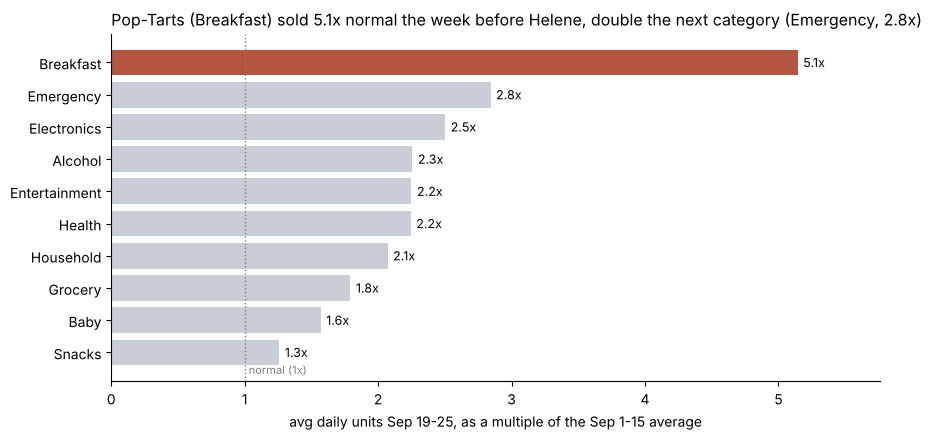

PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6


6

In [12]:
# ---- AFTER: one iteration. The claim is a ranking, so show the ranking: every category's
# surge multiple, sorted, on a common baseline, with Breakfast highlighted and the 1x line marked.
m = q1['multiple'].sort_values()
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(m.index, m.values, color=['#b4553f' if c == top else '#c9cdd6' for c in m.index])
ax.bar_label(bars, labels=[f'{v:.1f}x' for v in m.values], padding=4, fontsize=9)
ax.axvline(1.0, color='gray', ls=':', lw=1)
ax.text(1.03, -0.75, 'normal (1x)', fontsize=8, color='gray', va='bottom')
runner_up = q1.index[1]
ax.set_title(f"Pop-Tarts (Breakfast) sold {q1.loc[top, 'multiple']:.1f}x normal the week before Helene, "
             f"double the next category ({runner_up}, {q1.loc[runner_up, 'multiple']:.1f}x)",
             loc='left', fontsize=11.5)
ax.set_xlabel('avg daily units Sep 19-25, as a multiple of the Sep 1-15 average')
ax.set_xlim(0, m.max() * 1.12)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

score(title=True, axes=True, chart_type=True, scale=True, readable=True, ink=True)

**My score before:** 4/6  **After:** 6/6  **What I changed:** The midterm Q1 chart had a good title and an honest, indexed scale, but the title claims a *ranking* ("Pop-Tarts at 5.1x, no other category reached 3x") while the chart showed five daily lines tangling in the surge window, with the reader matching colors to a legend and five of the ten categories left off. I replaced it with a sorted horizontal bar of the one number the claim rests on, the Sept 19–25 surge multiple for every category. Breakfast is highlighted and everything else is grey, there is a 1x "normal" reference line and value labels, and the title now makes the comparison explicit: 5.1x, double the runner-up. The day-by-day shape (the Sept 16 step, the peak on Sept 25) is a different claim; it belongs in its own chart and should not be packed into this one.

---

## Checkpoint (participation)

Report the rubric score of your own midterm chart before and after your redesign, and what you changed.

Work the last few minutes in groups of 4–5, then fill in the cell below **yourself**. Paste the printed output (or a screenshot of it) into this week's **Studio Checkpoint** in Canvas by **Wednesday 11:59pm ET**. One submission per person, not per group.

In [13]:
# Checkpoint
chart_i_fixed = 'Q1 surge chart: category demand indexed to the Sep 1-15 baseline, Hurricane Helene (2026-10-30 progress lab)'
score_before = 4           # failed: right chart for the question, readable
score_after = 6
new_title = ('Pop-Tarts (Breakfast) sold 5.1x normal the week before Helene, '
             f'double the next category ({runner_up}, {q1.loc[runner_up, "multiple"]:.1f}x)')

print('chart:', chart_i_fixed)
print('score:', score_before, '->', score_after)
print('new title:', new_title)

chart: Q1 surge chart: category demand indexed to the Sep 1-15 baseline, Hurricane Helene (2026-10-30 progress lab)
score: 4 -> 6
new title: Pop-Tarts (Breakfast) sold 5.1x normal the week before Helene, double the next category (Emergency, 2.8x)
